# DL090 音频、视频与时间结构

本Notebook在新Python进程的真实IPython内核内顺序执行，完整运行实验和测试。先读 lecture.md 与 lab.md。只验证离线合成教学任务，不代表自然数据性能或部署保证。

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import experiment as exp
print("Python",sys.version.split()[0],"NumPy",np.__version__)

Python 3.12.14 NumPy 2.3.5


## 完整重训与数据保存
运行覆盖本目录 outputs 和 figures 中的同名文件；无下载、无GPU、无付费API。

In [2]:
result=exp.main("outputs")

{"stft_shape": [480, 61, 129], "group_overlap": 0, "random_clip_split_source_overlap": 36, "elapsed_seconds_before_plotting": 0.804623169999104}
temporal 11 1.0 0.5208333333333334
pooled 11 0.53125 0.53125
shuffle_train 11 0.0 0.5208333333333334
temporal 23 1.0 0.4583333333333333
pooled 23 0.5104166666666666 0.5104166666666666
shuffle_train 23 0.0 0.5104166666666666
temporal 37 1.0 0.5833333333333334
pooled 37 0.5104166666666666 0.5104166666666666
shuffle_train 37 1.0 0.5625


## 核对分帧与标签时间

In [3]:
x,y,g,p=exp.generate(sources=2,pairs=1)
spec=exp.stft(x)
print("wave",x.shape,"STFT",spec.shape,"features",exp.features(exp.band_features(spec)).shape)
starts,centers,overlap=exp.alignment_report()
print("frame 30:",starts[30],centers[30],overlap[30])

wave (4, 4096) STFT (4, 61, 129) features (4, 8)
frame 30: 1920 0.2559375 0.5000000000000004


## 所有固定种子结果

In [4]:
for row in result["runs"]:
    print(row["method"],row["seed"],"ordered",row["test_accuracy"],"shuffled",row["shuffle_test_accuracy"])
print("Source overlap:",result["group_overlap"],"random split overlap:",result["random_clip_split_source_overlap"])

temporal 11 ordered 1.0 shuffled 0.5208333333333334
pooled 11 ordered 0.53125 shuffled 0.53125
shuffle_train 11 ordered 0.0 shuffled 0.5208333333333334
temporal 23 ordered 1.0 shuffled 0.4583333333333333
pooled 23 ordered 0.5104166666666666 shuffled 0.5104166666666666
shuffle_train 23 ordered 0.0 shuffled 0.5104166666666666
temporal 37 ordered 1.0 shuffled 0.5833333333333334
pooled 37 ordered 0.5104166666666666 shuffled 0.5104166666666666
shuffle_train 37 ordered 1.0 shuffled 0.5625
Source overlap: 0 random split overlap: 36


## 单元测试
检查计算与边界，不只观察训练损失。

In [5]:
import unittest
suite=unittest.defaultTestLoader.discover(str(Path.cwd()),pattern="test_experiment.py")
check=unittest.TextTestRunner(verbosity=2).run(suite)
if not check.wasSuccessful(): raise RuntimeError("tests failed")

test_alias (test_experiment.TestAudio.test_alias) ... 

ok


test_alignment (test_experiment.TestAudio.test_alignment) ... 

ok


test_chunk_swap (test_experiment.TestAudio.test_chunk_swap) ... 

...

test_shape (test_experiment.TestAudio.test_shape) ... 

ok


test_short_input (test_experiment.TestAudio.test_short_input) ... 

ok


----------------------------------------------------------------------
Ran 10 tests in 0.025s

OK


## 保存文件的独立推理重放

In [6]:
import verify_replay
replay=verify_replay.main("outputs")
print(replay)

{"status": "passed", "probability_arrays_replayed": 18, "max_probability_error": 0.0, "feature_reconstruction": "passed", "training_only_mean": "passed"}
{'status': 'passed', 'probability_arrays_replayed': 18, 'max_probability_error': 0.0, 'feature_reconstruction': 'passed', 'training_only_mean': 'passed'}


## 原创图的真实结果
图为本次实验直接重建。

01_audio_spectrogram.png


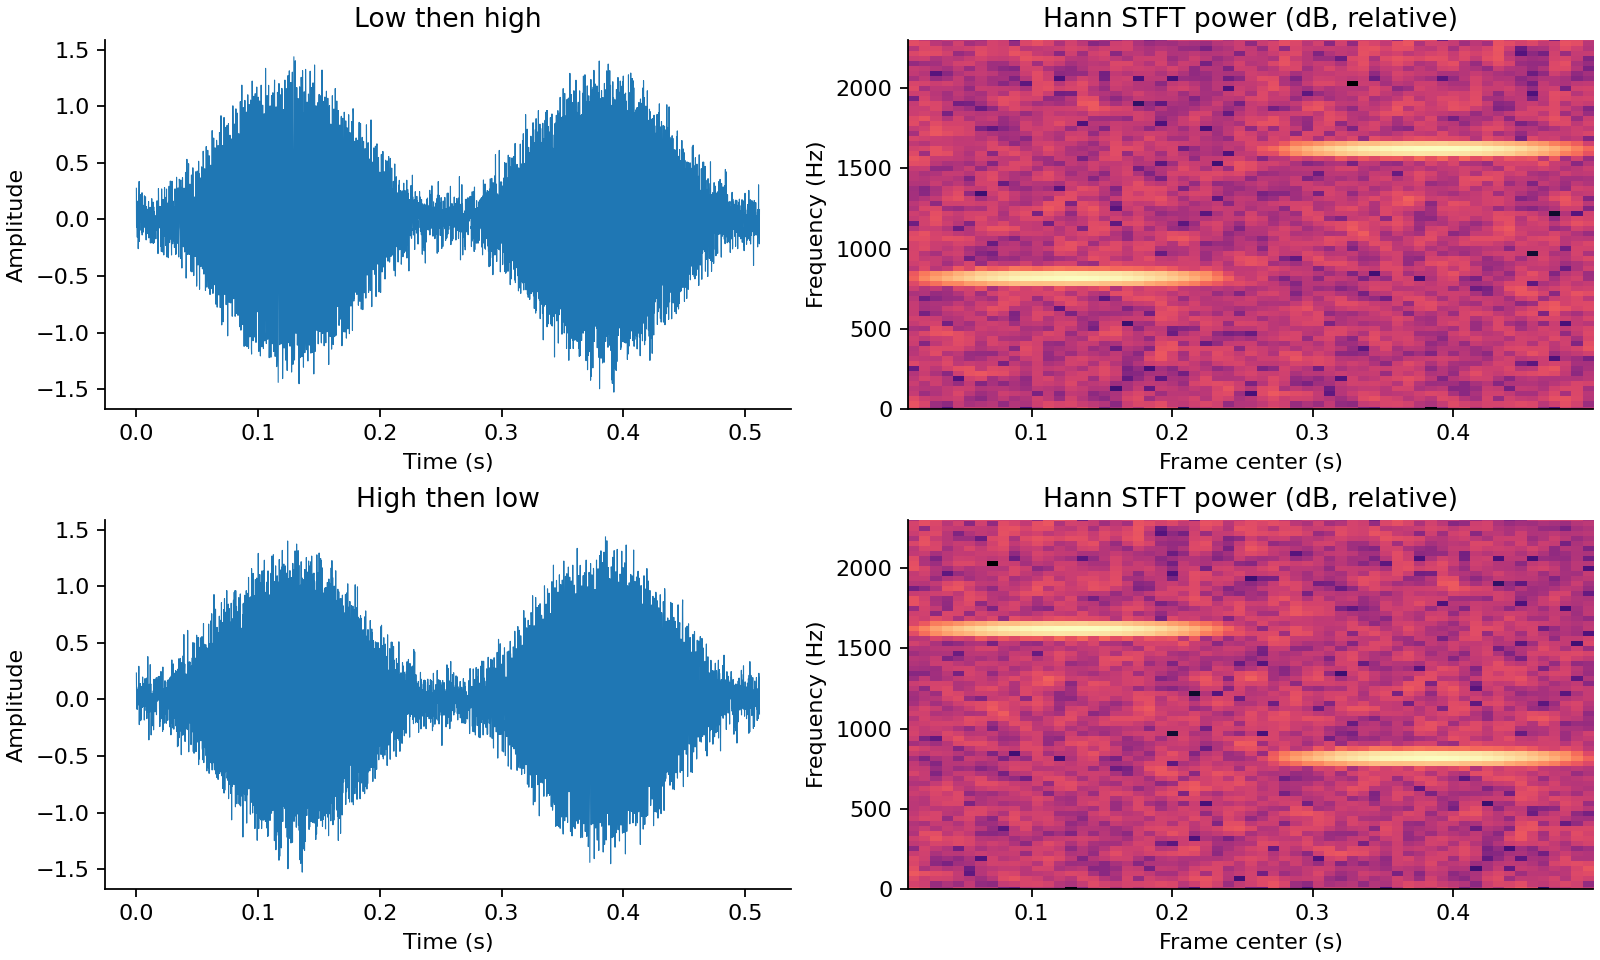

02_sampling_window.png


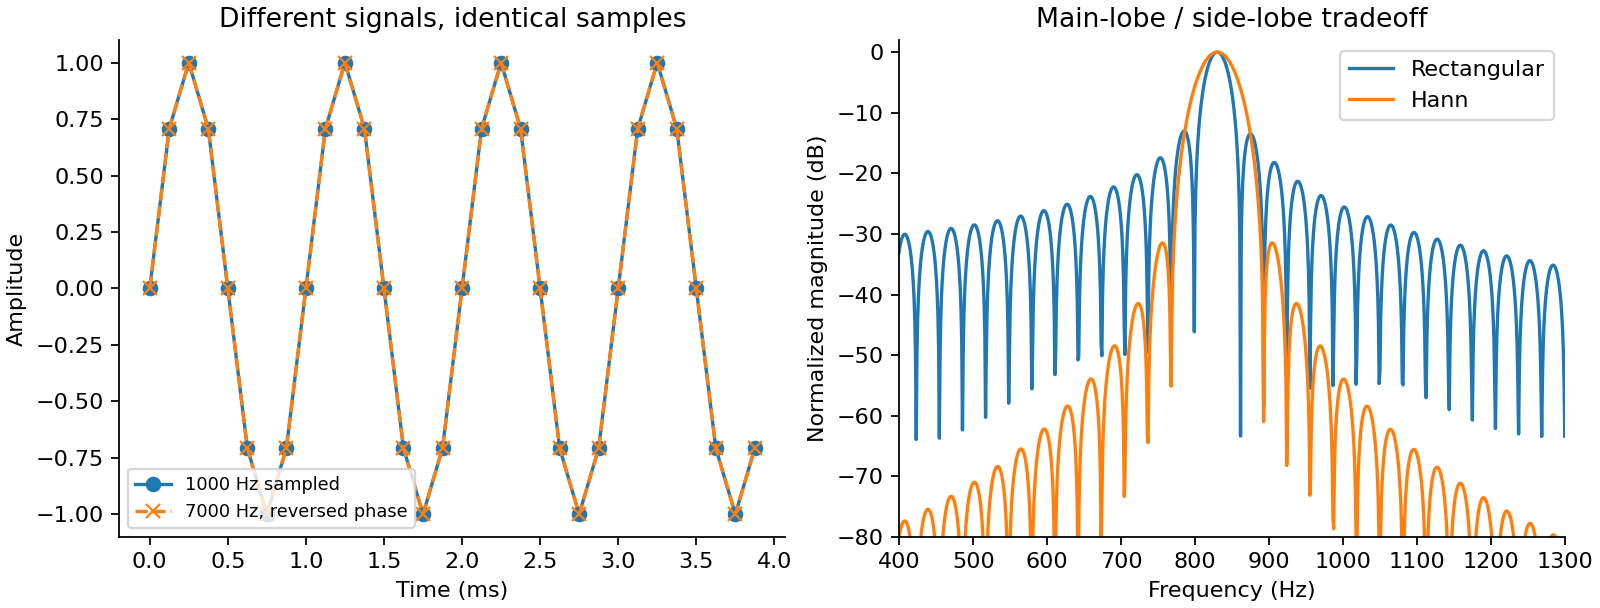

03_label_alignment.png


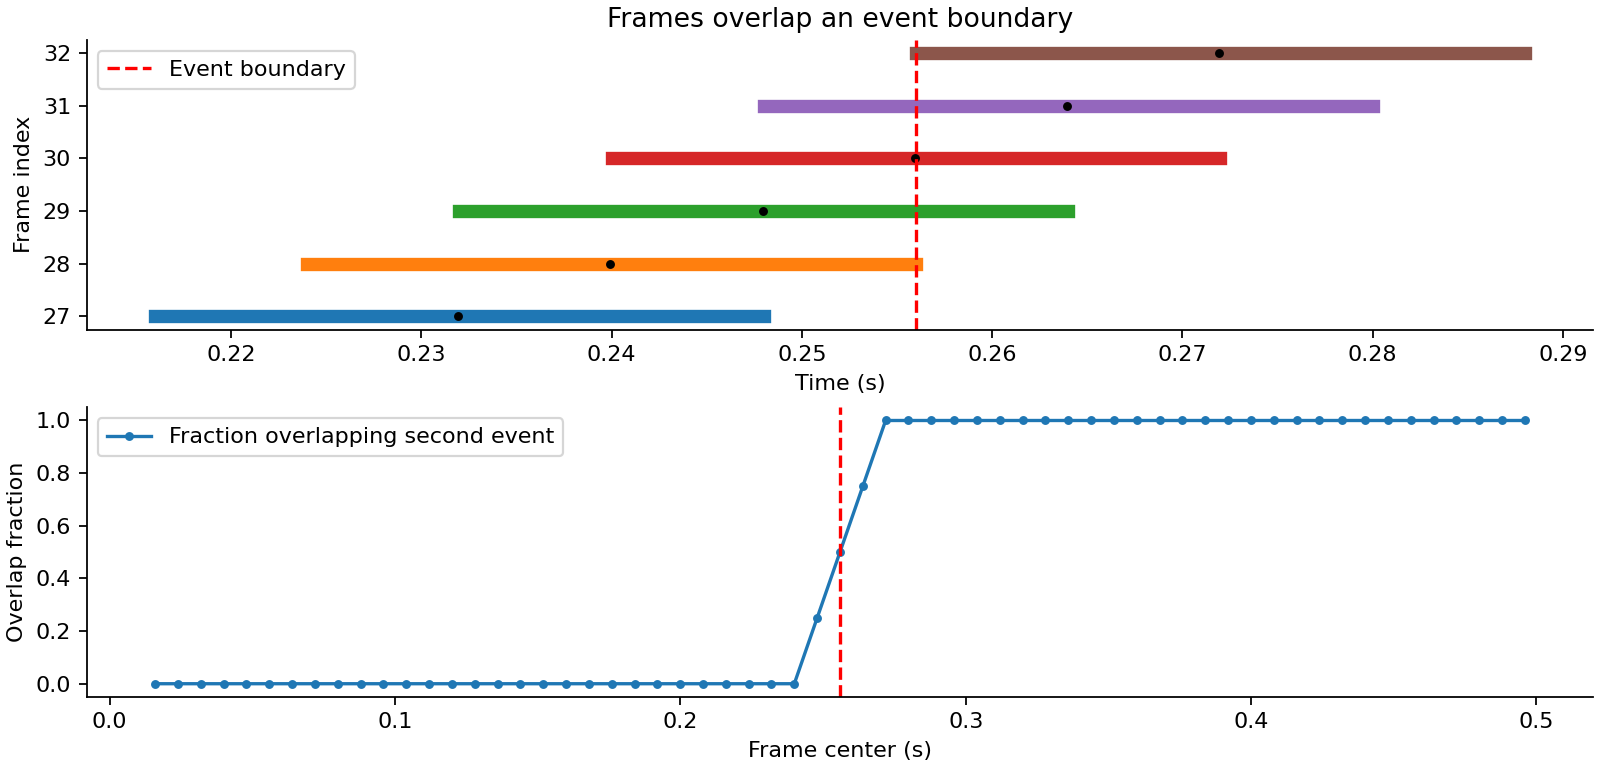

04_temporal_controls.png


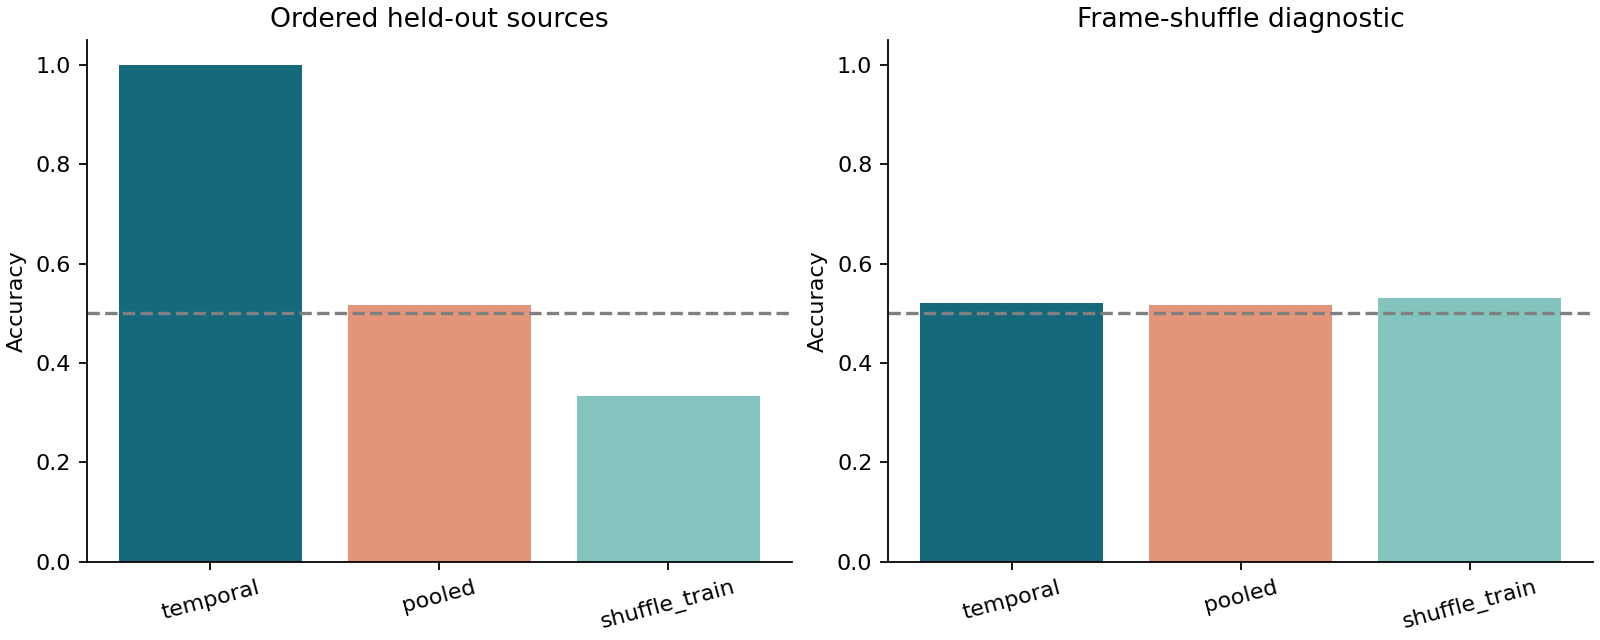

05_split_training.png


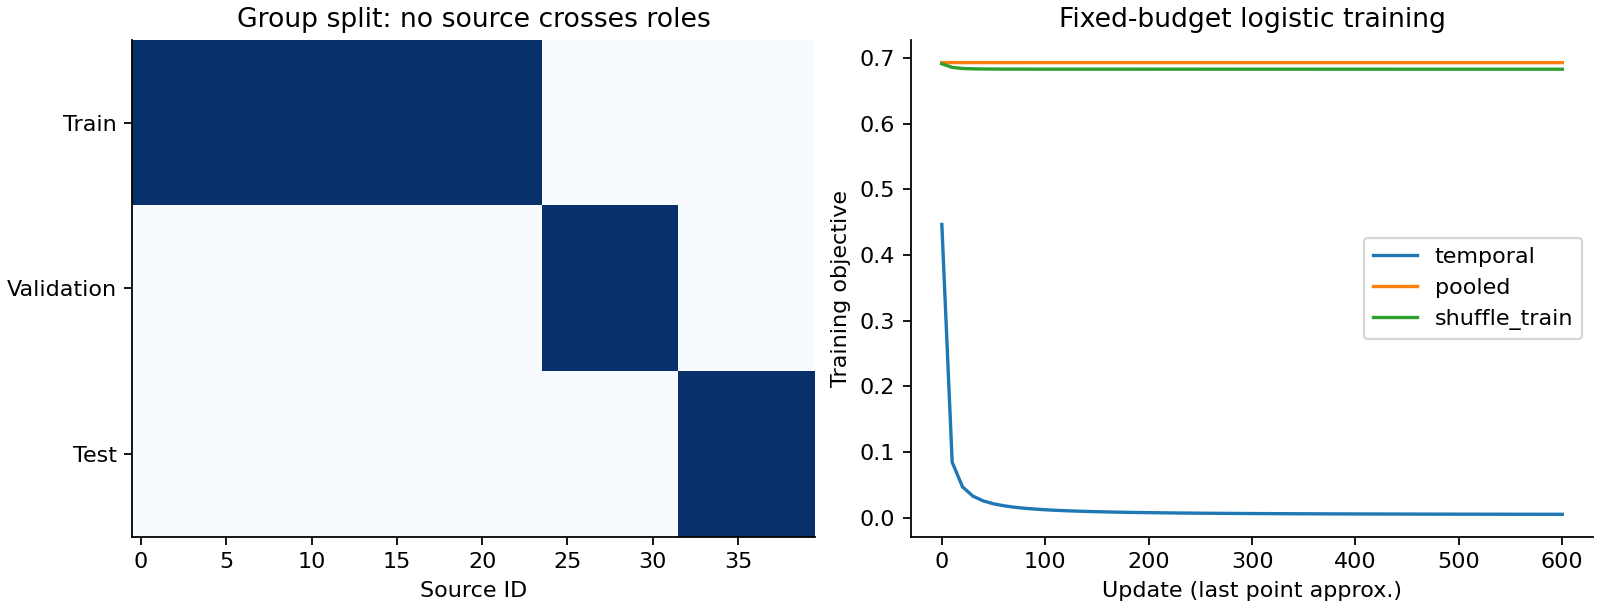

In [7]:
from IPython.display import display,Image
for path in sorted(Path("figures").glob("*.png")):
    print(path.name)
    display(Image(filename=str(path)))

## 研究记录
请写下一个受证据支持的主张、一个负结果或限制、一个明确的新检验。不要用参考答案替代自己的数据检查。

In [8]:
print("Saved outputs:",sorted(p.name for p in Path("outputs").iterdir() if p.is_file()))

Saved outputs: ['alignment.csv', 'data.npz', 'metrics.json', 'notebook-execution.json', 'predictions.npz', 'replay-verification.json', 'results.csv', 'weights.npz']
